**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Classificação de fraturas em afloramento com CNN e AlexNet

Laboratório: [Identifying Rock Crack by Convolutional Neural Network](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.CNN/Chapter.CNNCrack/lab.html) (S. Feng), pacote `CNN_lab.zip`, extraído em `CNN_lab/`.

A imagem é uma foto de afloramento em tons de cinza com $457\times977$ pixels. Cada pixel é representado pela janela de $17\times17$ px centrada nele, e uma CNN classifica a janela como **fratura** ($y=1$) ou **não fratura** ($y=0$). Classificando todos os pixels, obtém-se o mapa de fraturas.

O enunciado pede a AlexNet, mas o código do lab (`test_example_CNN.m` e a pasta `CNN/`, adaptados do DeepLearnToolbox de R. B. Palm) usa uma CNN pequena, com duas camadas convolucionais. O notebook usa as duas:

* **CNN do lab:** `cnnsetup.m`, `cnnff.m`, `cnnbp.m` e `cnntrain.m` traduzidos para PyTorch, com os mesmos hiperparâmetros;
* **AlexNet:** pré-treinada no ImageNet e ajustada às mesmas janelas (*transfer learning*), como no exemplo *Transfer Learning Using AlexNet* do MATLAB.

As seções 1 a 4 refazem o lab com os pontos de treino do pacote. A seção 5 refaz o picking dos pontos "não fratura", porque os do pacote têm um problema sério (seção 1). A seção 6 responde às quatro questões do lab, e a seção 7 interpreta os resultados.

**Como executar:** use o ambiente `.venv` do projeto (PyTorch para CPU). As seções 5 e 6.3 abrem figuras clicáveis para o picking. Elas precisam do pacote `ipympl`, já instalado no `.venv`; se acabou de instalá-lo, reinicie o kernel. Na primeira execução, os pesos da AlexNet (233 MB) são baixados. A execução completa leva cerca de 15 min numa CPU de 8 núcleos, quase todo esse tempo na AlexNet.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import scipy.io as sio
from scipy import ndimage as ndi
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import alexnet, AlexNet_Weights
from IPython.display import Markdown, display
import ipywidgets as widgets

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
SEMENTE = 0          # inicialização, ordem dos minilotes e divisão treino/validação
DADOS = Path('CNN_lab/CNN_lab/data')
COR = {'CNN do lab': '#2a78d6', 'AlexNet': '#eb6834'}
FRATURA = ListedColormap(['#1a1a19', '#f0c419'])                                  # não fratura, fratura
CONCORDA = ListedColormap(['#1a1a19', COR['CNN do lab'], COR['AlexNet'], '#f0efec'])
RES = {}             # resumo de cada experimento, reunido na seção 7

## 1. Imagem e pontos de treino do lab

`image_input.mat` traz a imagem, com valores em $[-1, 1]$. `train_new.mat` traz os pontos de treino: as coordenadas `trainx` e `trainz`, vindas do `ginput`, e o rótulo *one-hot* `label` ($2\times400$, primeira linha = fratura). O `test_example_CNN.m` carrega esse arquivo, e o código de picking com `ginput` está comentado.

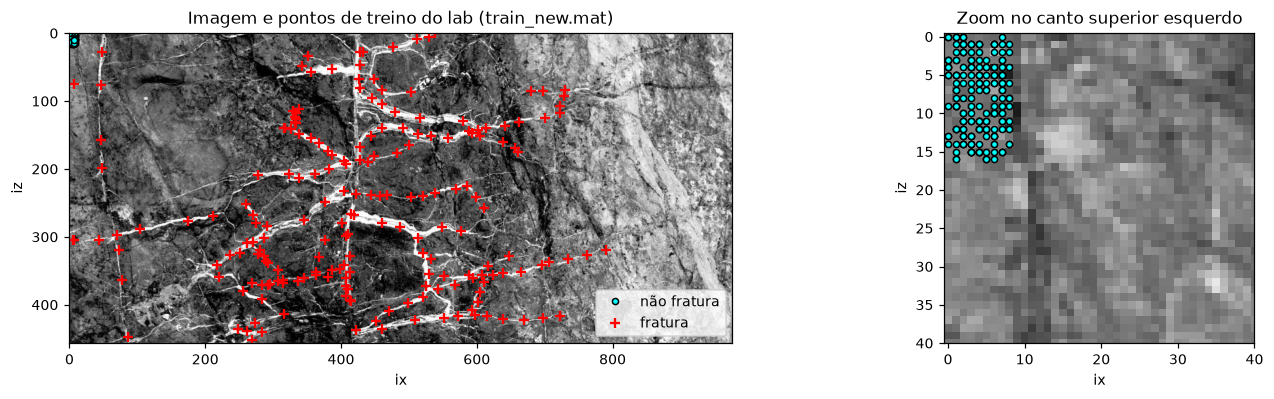

200 pontos de fratura: ix de 5 a 791, iz de 0 a 452
200 pontos não fratura: ix de 0 a 8, iz de 0 a 16, 105 posições distintas


In [2]:
img = sio.loadmat(DADOS / 'image_input.mat')['image_input'].astype(np.float32)
nz, nx = img.shape
tr = sio.loadmat(DADOS / 'train_new.mat', squeeze_me=True, struct_as_record=False)['train']
lab = pd.DataFrame({'ix': tr.trainx.astype(int) - 1, 'iz': tr.trainz.astype(int) - 1,   # o MATLAB indexa a partir de 1
                    'classe': tr.label[0].astype(int)})                                   # 1ª linha do one-hot: 1 = fratura
ESTILO = {0: dict(marker='o', mfc='cyan', mec='k', ms=4, label='não fratura'),
          1: dict(marker='+', color='r', mew=1.5, ms=6, label='fratura')}


def mostra(a, conj=None, titulo='', estilo=ESTILO):
    a.imshow(img, cmap='gray', vmin=-1, vmax=1)
    if conj is not None:
        for c, e in estilo.items():
            s = conj[conj.classe == c]
            a.plot(s.ix, s.iz, ls='none', **e)
    a.set_title(titulo); a.set_xlabel('ix'); a.set_ylabel('iz')


fig, ax = plt.subplots(1, 2, figsize=(13, 3.7), gridspec_kw={'width_ratios': [nx / nz, 1]})
mostra(ax[0], lab, 'Imagem e pontos de treino do lab (train_new.mat)'); ax[0].legend(loc='lower right')
mostra(ax[1], lab, 'Zoom no canto superior esquerdo'); ax[1].set_xlim(-0.5, 40); ax[1].set_ylim(40, -0.5)
plt.tight_layout(); plt.show()

fr, nf = lab[lab.classe == 1], lab[lab.classe == 0]
print(f'{len(fr)} pontos de fratura: ix de {fr.ix.min()} a {fr.ix.max()}, iz de {fr.iz.min()} a {fr.iz.max()}')
print(f'{len(nf)} pontos não fratura: ix de {nf.ix.min()} a {nf.ix.max()}, iz de {nf.iz.min()} a {nf.iz.max()}, '
      f'{len(nf.drop_duplicates(["ix", "iz"]))} posições distintas')

**Problema nos pontos do lab.** Os 200 pontos de fratura acompanham as fraturas da metade esquerda da imagem (ix ≤ 791). Já os 200 pontos "não fratura" estão todos no canto superior esquerdo, numa área de 9 × 17 px, e só 105 posições são distintas. Como a janela tem 17 × 17 px e a borda é replicada (`padimage.m`), as 200 janelas "não fratura" são recortes quase iguais do mesmo canto. A rede aprende a separar as fraturas *desse canto*, e não do resto da rocha. A faixa clara da direita (ix ≳ 700) não tem nenhum ponto. A seção 4 mostra a consequência.

## 2. CNN do lab (tradução de `cnnsetup.m`, `cnnff.m`, `cnnbp.m` e `cnntrain.m`)

* **Janelas (Step 2):** `padimage` replica as bordas da imagem, e a janela de $17\times17$ px (`wdx = wdz = 8`) é interpolada bilinearmente para $32\times32$ (`interp2`), para que as dimensões antes de cada *pooling* sejam pares.
* **Arquitetura (Fig. 2 do lab):** conv 6@5×5 → média 2×2 → conv 12@5×5 → média 2×2 → vetor de 300 → camada totalmente conectada com 2 saídas, num total de 2 570 parâmetros. Todas as camadas usam sigmoide: a figura do lab fala em ReLU, mas o `cnnff.m` usa `sigm`.
* **Custo (`cnnbp.m`):** quadrático, $C(w,b)=\frac{1}{2n}\sum_x\lVert y(x)-a\rVert^2$, com $y(x)$ o rótulo *one-hot* e $a$ a saída da rede.
* **Treino (`cnntrain.m`):** SGD sem momento, passo $\alpha=1$, minilotes de 20 e 10 épocas, com a ordem dos pontos sorteada a cada época. Os pesos começam uniformes em $\pm\sqrt{6/(\text{fan}_\text{in}+\text{fan}_\text{out})}$ e os vieses, nulos (`cnnsetup.m`).
* **Classificação (Step 4):** a janela de cada um dos 446 489 pixels passa pela rede, e a classe é a saída de maior valor.

O lab treina com os 400 pontos. Aqui, 20 % dos pontos de cada classe ficam fora do treino (**validação**), para medir o acerto em pontos que a rede não viu. Os argumentos `moderna`, `aumentar` e `l2` só são usados nas questões 2 e 3.

In [3]:
WD, NOVO, PAD = 8, 32, 16                  # janela de 17 x 17 px (wdx = wdz = 8) interpolada para 32 x 32
img_pad = np.pad(img, PAD, mode='edge')     # padimage.m: replica as bordas


def janelas(iz, ix, wd=WD):
    # image_slice do test_example_CNN.m: janela (2wd+1) x (2wd+1) centrada em cada (iz, ix)
    o = np.arange(-wd, wd + 1) + PAD
    return torch.from_numpy(img_pad[iz[:, None, None] + o[None, :, None], ix[:, None, None] + o[None, None, :]])


class CNNLab(nn.Module):
    # cnnsetup.m + cnnff.m: conv 5x5 -> média 2x2 -> conv 5x5 -> média 2x2 -> totalmente conectada
    def __init__(self, n_saidas=2, mapas=(6, 12), k=5, moderna=False):
        super().__init__()
        self.moderna = moderna                                    # ReLU + max-pooling + entropia cruzada (questão 2)
        self.c1, self.c2 = nn.Conv2d(1, mapas[0], k), nn.Conv2d(mapas[0], mapas[1], k)
        lado = ((NOVO - k + 1) // 2 - k + 1) // 2                 # 32 -> 28 -> 14 -> 10 -> 5
        self.fc = nn.Linear(mapas[1] * lado**2, n_saidas)
        for c in (self.c1, self.c2):                              # inicialização do cnnsetup.m
            r = np.sqrt(6 / ((c.in_channels + c.out_channels) * k * k))
            nn.init.uniform_(c.weight, -r, r); nn.init.zeros_(c.bias)
        r = np.sqrt(6 / (n_saidas + self.fc.in_features))
        nn.init.uniform_(self.fc.weight, -r, r); nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = F.interpolate(x[:, None], size=NOVO, mode='bilinear', align_corners=True)   # interp2 para 32 x 32
        ativ, pool = (F.relu, F.max_pool2d) if self.moderna else (torch.sigmoid, F.avg_pool2d)
        x = self.fc(pool(ativ(self.c2(pool(ativ(self.c1(x)), 2))), 2).flatten(1))
        return x if self.moderna else torch.sigmoid(x)            # saída j: pontuação da classe j


def custo(net, s, y):
    if net.moderna:
        return F.cross_entropy(s, y)
    return 0.5 * ((s - F.one_hot(y, s.shape[1]).float()) ** 2).sum() / len(y)            # cnnbp.m


def dividir(conj, frac_val=0.2, seed=SEMENTE):
    # separa 20 % dos pontos de cada classe para validação
    r = np.random.default_rng(seed)
    val = np.zeros(len(conj), bool)
    for c in np.unique(conj.classe):
        i = np.flatnonzero(conj.classe.values == c)
        val[r.choice(i, round(frac_val * len(i)), replace=False)] = True
    return conj.reset_index(drop=True).assign(val=val)


def girar(x):
    # aumento de dados (questão 3): rotação de k x 90° e espelhamento sorteados para cada janela
    k, e = torch.randint(4, (len(x),)), torch.rand(len(x)) < 0.5
    x = torch.stack([torch.rot90(j, int(q)) for j, q in zip(x, k)])
    x[e] = x[e].flip(-1)
    return x


def historico(net, s, y, sv, yv):
    return {'custo treino': custo(net, s, y).item(), 'custo validação': custo(net, sv, yv).item(),
            'acerto treino': (s.argmax(1) == y).float().mean().item(), 'acerto validação': (sv.argmax(1) == yv).float().mean().item()}


def treinar_cnn_lab(conj, epocas=10, alfa=1.0, lote=20, wd=WD, aumentar=False, l2=0.0, seed=SEMENTE, **arq):
    # cnntrain.m: SGD sem momento; a cada época, sorteia a ordem dos pontos e percorre os minilotes
    torch.manual_seed(seed)
    net = CNNLab(n_saidas=conj.classe.max() + 1, **arq)
    net.wd = wd
    X, y = janelas(conj.iz.values, conj.ix.values, wd), torch.tensor(conj.classe.values)
    v = torch.tensor(conj.val.values)
    Xt, yt, Xv, yv = X[~v], y[~v], X[v], y[v]
    opt = torch.optim.SGD(net.parameters(), lr=alfa, weight_decay=l2)
    hist, t0 = [], time.perf_counter()
    for _ in range(epocas):
        ordem = torch.randperm(len(yt))
        for b in range(len(yt) // lote):
            i = ordem[b * lote:(b + 1) * lote]
            xb = girar(Xt[i]) if aumentar else Xt[i]
            opt.zero_grad(); custo(net, net(xb), yt[i]).backward(); opt.step()
        with torch.no_grad():
            hist.append(historico(net, net(Xt), yt, net(Xv), yv))
    net.tempo = time.perf_counter() - t0
    net.hist = pd.DataFrame(hist, index=pd.RangeIndex(1, epocas + 1, name='época'))
    return net


def mapa_cnn_lab(net, colunas=40):
    # Step 4 do test_example_CNN.m: classifica a janela de todos os pixels, em blocos de colunas
    S = np.zeros((net.fc.out_features, nz, nx), np.float32)
    t0 = time.perf_counter()
    with torch.no_grad():
        for j in range(0, nx, colunas):
            Z, X = np.meshgrid(np.arange(nz), np.arange(j, min(j + colunas, nx)), indexing='ij')
            S[:, :, j:j + colunas] = net(janelas(Z.ravel(), X.ravel(), net.wd)).T.reshape(-1, *Z.shape).numpy()
    net.tempo_mapa = time.perf_counter() - t0
    return S.argmax(0)

## 3. AlexNet (*transfer learning*)

* **Rede:** AlexNet do `torchvision` com pesos do ImageNet, com 5 camadas convolucionais e 3 totalmente conectadas. A última camada (fc8, 1 000 classes) é trocada por uma com 2 saídas, e a rede fica com 57 M parâmetros.
* **Entrada:** a mesma janela de $17\times17$ px da CNN do lab, interpolada para $224\times224$, repetida nos 3 canais RGB e normalizada com a média e o desvio do ImageNet.
* **Treino:** como no exemplo do MATLAB (`sgdm`, `MiniBatchSize = 10`, `MaxEpochs = 6`, `InitialLearnRate = 1e-4`, `L2Regularization = 1e-4`, e `WeightLearnRateFactor = BiasLearnRateFactor = 20` na camada nova). Ou seja: SGD com momento 0,9, passo $10^{-4}$ nas camadas pré-treinadas e $2\times10^{-3}$ na nova, e entropia cruzada como custo.
* **Classificação:** em CPU, a AlexNet processa ~230 janelas/s, e os 446 489 pixels levariam ~33 min. Por isso ela classifica uma grade com passo de 4 px ($115\times245$ = 28 175 janelas, ~2 min), e a probabilidade de cada classe é interpolada bilinearmente para todos os pixels. A janela tem 17 px, quatro vezes o passo, então o mapa perde pouco detalhe.

In [4]:
PESOS = AlexNet_Weights.IMAGENET1K_V1
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)       # normalização do ImageNet
DESVIO = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def entrada_alexnet(x):
    # janela em [-1, 1] -> imagem 3 x 224 x 224 em tons de cinza, normalizada como no ImageNet
    x = F.interpolate(x[:, None], size=224, mode='bilinear', align_corners=True)
    return ((x + 1) / 2 - MEDIA) / DESVIO


def treinar_alexnet(conj, epocas=6, lote=10, seed=SEMENTE):
    torch.manual_seed(seed)
    net = alexnet(weights=PESOS)
    net.classifier[6] = nn.Linear(4096, conj.classe.max() + 1)          # troca a fc8 (1000 classes do ImageNet)
    net.moderna = True                                                  # custo: entropia cruzada
    nova = list(net.classifier[6].parameters())
    base = [p for n, p in net.named_parameters() if not n.startswith('classifier.6')]
    opt = torch.optim.SGD([{'params': base, 'lr': 1e-4}, {'params': nova, 'lr': 20 * 1e-4}], momentum=0.9, weight_decay=1e-4)
    X, y = janelas(conj.iz.values, conj.ix.values), torch.tensor(conj.classe.values)
    v = torch.tensor(conj.val.values)
    Xt, yt, Xv, yv = X[~v], y[~v], X[v], y[v]
    hist, t0 = [], time.perf_counter()
    for _ in range(epocas):
        net.train()                                                     # liga o dropout das camadas fc6 e fc7
        ordem = torch.randperm(len(yt))
        for b in range(0, len(yt), lote):
            i = ordem[b:b + lote]
            opt.zero_grad(); F.cross_entropy(net(entrada_alexnet(Xt[i])), yt[i]).backward(); opt.step()
        net.eval()
        with torch.inference_mode():
            hist.append(historico(net, net(entrada_alexnet(Xt)), yt, net(entrada_alexnet(Xv)), yv))
    net.tempo = time.perf_counter() - t0
    net.hist = pd.DataFrame(hist, index=pd.RangeIndex(1, epocas + 1, name='época'))
    return net


def mapa_alexnet(net, passo=4, lote=256):
    # classifica uma grade com passo de 4 px e interpola a probabilidade de cada classe para todos os pixels
    gz, gx = np.arange(0, nz, passo), np.arange(0, nx, passo)
    assert gz[-1] == nz - 1 and gx[-1] == nx - 1                        # a grade cobre a imagem até a borda
    Z, X = (a.ravel() for a in np.meshgrid(gz, gx, indexing='ij'))
    P, t0 = [], time.perf_counter()
    with torch.inference_mode():
        for b in range(0, len(Z), lote):
            P.append(F.softmax(net(entrada_alexnet(janelas(Z[b:b + lote], X[b:b + lote]))), 1))
    P = torch.cat(P).T.reshape(1, -1, len(gz), len(gx))
    net.tempo_mapa = time.perf_counter() - t0
    return F.interpolate(P, size=(nz, nx), mode='bilinear', align_corners=True)[0].argmax(0).numpy()

## 4. Resultado com os pontos do lab

Os dois modelos são treinados com os pontos do `train_new.mat`. Para avaliar os mapas sem um rótulo verdadeiro para cada pixel, a tabela usa três medidas:

* **fratura em ix ≥ 800:** fração de pixels classificados como fratura na faixa clara da direita, onde o lab não marcou nenhuma fratura;
* **regiões de fratura:** número de regiões conectadas (vizinhança de 8) no mapa de fraturas;
* **fratura em regiões < 50 px:** fração dos pixels de fratura que estão em manchas isoladas menores que 50 px. Uma fratura real é alongada e contínua, então essas manchas são, em geral, ruído.

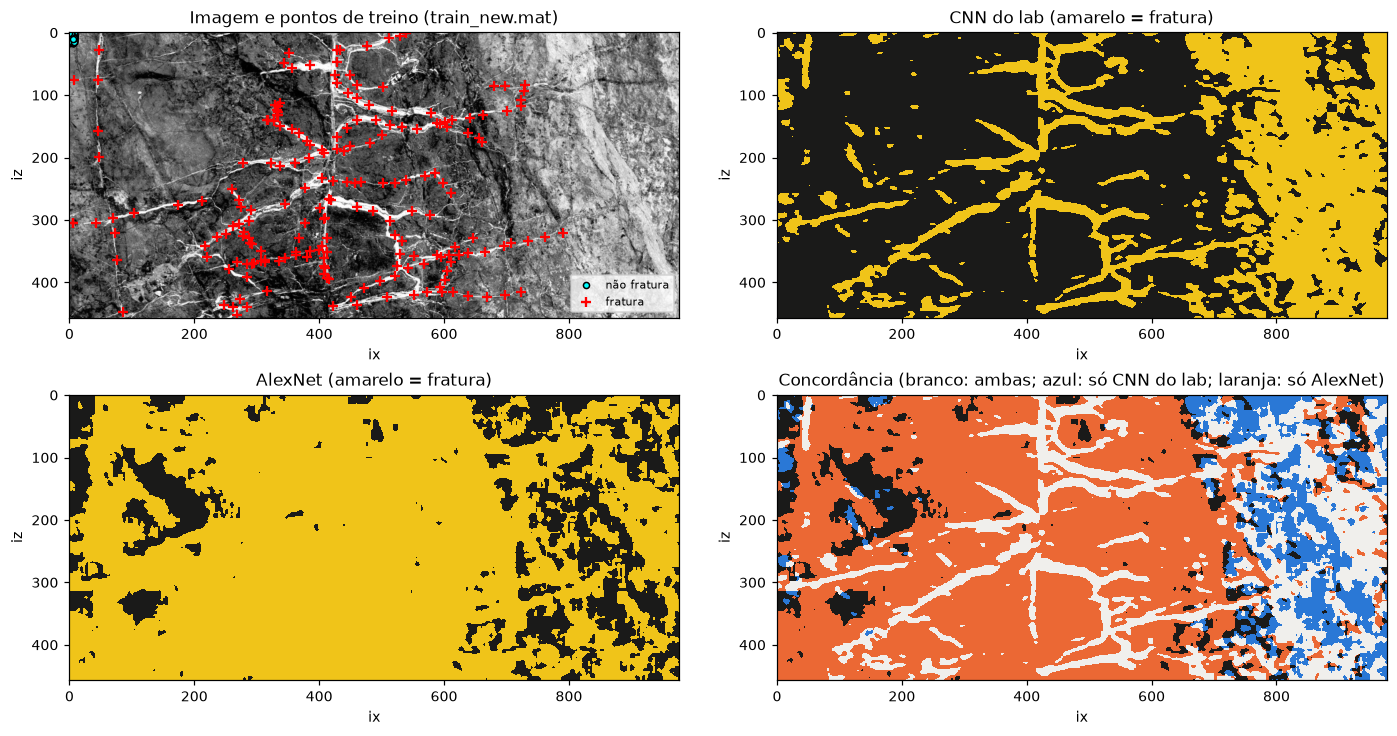

,CNN do lab,AlexNet
acerto treino (%),82.5,100.0
acerto validação (%),83.7,100.0
pixels fratura (%),33.3,81.0
fratura em ix ≥ 800 (%),83.2,59.5
regiões de fratura,151,70
fratura em regiões < 50 px (%),0.9,0.2
tempo de treino (s),0.4,85.7
tempo do mapa (s),10.6,132.8
parâmetros,2 570,57 012 034


In [5]:
CLARA = slice(800, None)            # colunas da faixa clara da direita


def fragmentos(c, min_px=50):
    rot, n = ndi.label(c > 0, structure=np.ones((3, 3)))
    tam = np.bincount(rot.ravel())[1:]
    return n, 100 * tam[tam < min_px].sum() / max(tam.sum(), 1)


def resumo(net, c):
    h, (n, frag) = net.hist.iloc[-1], fragmentos(c)
    return {'acerto treino (%)': 100 * h['acerto treino'], 'acerto validação (%)': 100 * h['acerto validação'],
            'pixels fratura (%)': 100 * (c > 0).mean(), 'fratura em ix ≥ 800 (%)': 100 * (c[:, CLARA] > 0).mean(),
            'regiões de fratura': n, 'fratura em regiões < 50 px (%)': frag,
            'tempo de treino (s)': net.tempo, 'tempo do mapa (s)': net.tempo_mapa,
            'parâmetros': sum(p.numel() for p in net.parameters())}


def tabela(linhas, transpor=False):
    inteiro = ('regiões de fratura', 'parâmetros')
    df = pd.DataFrame(linhas).apply(lambda col: pd.Series(
        [f'{v:,.0f}'.replace(',', ' ') if k in inteiro else f'{v:.1f}' for k, v in col.items()], index=col.index))
    display(df.T if transpor else df)


def desenha(a, c, titulo, cmap=FRATURA):
    a.imshow(c, cmap=cmap, vmin=0, vmax=cmap.N - 1, interpolation='nearest')
    a.set_title(titulo); a.set_xlabel('ix'); a.set_ylabel('iz')


def compara(c_lab, c_alex, conj, titulo):
    fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
    mostra(ax[0, 0], conj, f'Imagem e pontos de treino ({titulo})'); ax[0, 0].legend(loc='lower right', fontsize=7)
    desenha(ax[0, 1], c_lab, 'CNN do lab (amarelo = fratura)')
    desenha(ax[1, 0], c_alex, 'AlexNet (amarelo = fratura)')
    desenha(ax[1, 1], c_lab + 2 * c_alex, 'Concordância (branco: ambas; azul: só CNN do lab; laranja: só AlexNet)', CONCORDA)
    plt.tight_layout(h_pad=2); plt.show()


conj_lab = dividir(lab)
cnn_lab = treinar_cnn_lab(conj_lab); c_cnn_lab = mapa_cnn_lab(cnn_lab)
alex_lab = treinar_alexnet(conj_lab); c_alex_lab = mapa_alexnet(alex_lab)
compara(c_cnn_lab, c_alex_lab, conj_lab, 'train_new.mat')
RES['4. lab: CNN do lab'], RES['4. lab: AlexNet'] = resumo(cnn_lab, c_cnn_lab), resumo(alex_lab, c_alex_lab)
tabela({'CNN do lab': RES['4. lab: CNN do lab'], 'AlexNet': RES['4. lab: AlexNet']})

In [6]:
a, b = RES['4. lab: CNN do lab'], RES['4. lab: AlexNet']
display(Markdown(f'''
* **CNN do lab:** reproduz a Fig. 1b do lab. As fraturas da metade esquerda aparecem, mas {a['pixels fratura (%)']:.0f} % dos pixels são classificados como fratura, inclusive {a['fratura em ix ≥ 800 (%)']:.0f} % da faixa clara da direita.
* **AlexNet:** marca {b['pixels fratura (%)']:.0f} % da imagem como fratura. Quase tudo que não se parece com o canto superior esquerdo vira fratura.
* **Validação:** a CNN do lab acerta {a['acerto validação (%)']:.0f} % e a AlexNet, {b['acerto validação (%)']:.0f} % dos pontos de validação. Esses pontos têm o mesmo viés do treino (todos os "não fratura" estão no canto), então o acerto alto não diz nada sobre o resto da imagem.
'''))


* **CNN do lab:** reproduz a Fig. 1b do lab. As fraturas da metade esquerda aparecem, mas 33 % dos pixels são classificados como fratura, inclusive 83 % da faixa clara da direita.
* **AlexNet:** marca 81 % da imagem como fratura. Quase tudo que não se parece com o canto superior esquerdo vira fratura.
* **Validação:** a CNN do lab acerta 84 % e a AlexNet, 100 % dos pontos de validação. Esses pontos têm o mesmo viés do treino (todos os "não fratura" estão no canto), então o acerto alto não diz nada sobre o resto da imagem.


A rede mais expressiva erra mais, porque aprende exatamente o que os pontos ensinam: "não fratura" é a textura do canto superior esquerdo. A CNN do lab, com 2 570 parâmetros e sigmoides, aprende uma regra mais simples, próxima de "pixel claro no centro da janela = fratura". Essa regra funciona na metade esquerda, onde as fraturas são as feições mais claras, e falha na faixa clara da direita. O problema está nos dados de treino, e não na rede.

## 5. Novo picking: pontos "não fratura"

Os 200 pontos de fratura do lab estão bem distribuídos e são mantidos. Os pontos "não fratura" são refeitos à mão numa **figura interativa**, que faz o papel do `ginput` do `test_example_CNN.m`:

* **Clique esquerdo** marca um ponto "não fratura" (círculo ciano). As cruzes vermelhas são os pontos de fratura do lab, só como referência.
* **Desfazer último ponto** (botão acima da figura) ou **clique direito** remove o último ponto.
* Para dar zoom, use a lupa da barra da figura e desligue-a antes de voltar a clicar. Com a lupa ou a mão ativas, os cliques não marcam pontos.
* Ao completar os pontos, eles são gravados em `picks_nao_fratura.csv` (colunas `ix, iz, classe`). **Depois, execute a próxima célula.**

Se `picks_nao_fratura.csv` já existir, os pontos são reaproveitados. Para refazer o picking, ponha `REFAZER_NAO_FRATURA = True`; o arquivo anterior é guardado como `picks_nao_fratura_anterior.csv`.

**Dica:** espalhe os pontos por toda a imagem e por todos os tipos de rocha sem fratura: a matriz escura entre as fraturas, a faixa clara da direita (ix > 700), que o lab não amostrou, e as bordas da imagem. Decida se as feições lineares claras da faixa da direita são fraturas; se não forem, marque alguns pontos sobre elas. Clique na rocha, e não sobre as fraturas, mas ponha alguns pontos a poucos pixels delas, para a rede aprender onde a fratura termina.

In [ ]:
REFAZER_NAO_FRATURA = False
N_NAO_FRATURA = 200
ARQ_NAO_FRATURA = Path('picks_nao_fratura.csv')


class Picking:
    # Equivalente ao ginput do test_example_CNN.m. etapas: [(classe, n, nome, estilo, cor do título), ...]

    def __init__(self, ax, etapas, arquivo):
        self.ax, self.etapas, self.arquivo = ax, etapas, arquivo
        self.pontos, self.marcas, self.salvo = [], [], False
        self.atualizar()

    def faltam(self, etapa):
        return etapa[1] - sum(p[2] == etapa[0] for p in self.pontos)

    def etapa(self):
        return next((e for e in self.etapas if self.faltam(e) > 0), None)     # primeira etapa incompleta

    def clique(self, ev):
        if ev.inaxes is not self.ax or getattr(getattr(ev.canvas, 'toolbar', None), 'mode', ''):
            return                                            # fora da imagem ou zoom/pan ativo
        if ev.button == 3:
            self.desfazer()
        elif ev.button == 1 and (e := self.etapa()):
            ix = int(np.clip(round(ev.xdata), 0, nx - 1))
            iz = int(np.clip(round(ev.ydata), 0, nz - 1))
            if any((ix, iz) == p[:2] for p in self.pontos):
                return                                        # pixel já marcado
            self.pontos.append((ix, iz, e[0]))
            self.marcas.append(self.ax.plot(ix, iz, ls='none', **e[3])[0])
            self.atualizar()

    def desfazer(self, *_):
        if self.pontos:
            self.pontos.pop()
            self.marcas.pop().remove()
            self.atualizar()

    def atualizar(self):
        e = self.etapa()
        if e is None:
            np.savetxt(self.arquivo, np.array(self.pontos), fmt='%d', delimiter=',', header='ix,iz,classe', comments='')
            self.salvo = True
            txt, cor = f'Concluído: {len(self.pontos)} pontos salvos em {self.arquivo}. Execute a próxima célula.', 'green'
        else:
            if self.salvo:                                    # desfez depois de salvar: o arquivo deixa de valer
                self.arquivo.unlink(missing_ok=True); self.salvo = False
            txt, cor = f'Clique em {e[2]}: faltam {self.faltam(e)} de {e[1]}', e[4]
        self.ax.set_title(txt, color=cor)
        self.ax.figure.canvas.draw_idle()


def picking(etapas, arquivo, refazer, referencia=None):
    # abre a figura clicável, ou reaproveita os pontos já salvos em arquivo
    if arquivo.exists() and not refazer:
        print(f'Usando os pontos já salvos em {arquivo} (ponha o REFAZER correspondente em True para refazer).')
        return None
    try:                                                         # figura clicável dentro do notebook (ipympl)
        get_ipython().run_line_magic('matplotlib', 'widget')
        no_notebook = True
    except (ImportError, RuntimeError):                          # kernel sem ipympl: abre uma janela separada
        get_ipython().run_line_magic('matplotlib', 'tk')
        no_notebook = False
        print('ipympl não encontrado neste kernel: o picking abre numa janela separada (pip install ipympl e reinicie o kernel para clicar no notebook).')
    if arquivo.exists():
        arquivo.replace(arquivo.with_name(arquivo.stem + '_anterior.csv'))
    with plt.ioff():
        fig, ax = plt.subplots(figsize=(11, 5.6))
    mostra(ax, referencia, estilo={1: dict(marker='+', color='r', mew=1, ms=5)})
    fig.tight_layout()
    p = Picking(ax, etapas, arquivo)
    fig.canvas.mpl_connect('button_press_event', p.clique)
    if no_notebook:
        fig.canvas.header_visible = False
        botao = widgets.Button(description='Desfazer último ponto', icon='undo')
        botao.on_click(p.desfazer)
        display(widgets.VBox([botao, fig.canvas]))
    else:
        plt.show(block=False)
    return p


def carregar(arquivo):
    if not arquivo.exists():
        raise RuntimeError(f'Termine o picking na figura acima e execute esta célula de novo ({arquivo} ainda não existe).')
    plt.close('all')                                             # fecha a figura do picking
    get_ipython().run_line_magic('matplotlib', 'inline')       # volta às figuras estáticas
    return pd.read_csv(arquivo)


pick_nf = picking([(0, N_NAO_FRATURA, 'pontos NÃO FRATURA', ESTILO[0], 'darkcyan')], ARQ_NAO_FRATURA, REFAZER_NAO_FRATURA,
                  referencia=lab[lab.classe == 1])

In [ ]:
nao = carregar(ARQ_NAO_FRATURA)
novo = dividir(pd.concat([lab[lab.classe == 1], nao], ignore_index=True))
print(f'{(novo.classe == 1).sum()} pontos de fratura (lab) e {(novo.classe == 0).sum()} pontos não fratura (novo picking), '
      f'{(nao.ix >= 800).sum()} deles em ix ≥ 800')
fig, ax = plt.subplots(figsize=(11, 5.2))
mostra(ax, novo, 'Novo conjunto de treino'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 5.1 Resultado com o novo conjunto de treino

Mesmos modelos, hiperparâmetros e divisão treino/validação da seção 4. Só os pontos "não fratura" mudaram.

In [ ]:
cnn_novo = treinar_cnn_lab(novo); c_cnn_novo = mapa_cnn_lab(cnn_novo)
alex_novo = treinar_alexnet(novo); c_alex_novo = mapa_alexnet(alex_novo)
compara(c_cnn_novo, c_alex_novo, novo, 'novo picking')
RES['5. novo: CNN do lab'], RES['5. novo: AlexNet'] = resumo(cnn_novo, c_cnn_novo), resumo(alex_novo, c_alex_novo)
tabela({'CNN do lab': RES['5. novo: CNN do lab'], 'AlexNet': RES['5. novo: AlexNet']})
print(f'concordância CNN do lab × AlexNet: {100 * np.mean(c_cnn_novo == c_alex_novo):.1f} % dos pixels')

## 6. Questões do lab

A seção 6 do lab propõe quatro questões. As questões 2 e 3 usam o conjunto de treino da seção 5. As questões 1 e 4 precisam de um segundo picking, de fraturas grandes e pequenas, e por isso ficam no fim.

### 6.1 Questão 2: mudar a estrutura da CNN

> *Modify the structure of CNN. See how the CNN parameter will change the result.*

Partindo da CNN do lab, cada variante muda uma coisa:

* **mais mapas:** 12 e 24 mapas em vez de 6 e 12, com cerca de 4 vezes mais parâmetros;
* **janela de 33 px:** `wdx = wdz = 16`. A janela de $33\times33$ px vê mais contexto e é reduzida, e não ampliada, para $32\times32$;
* **ReLU + max-pooling + entropia cruzada:** a ativação, o *pooling* e o custo usados nas CNNs atuais, inclusive na AlexNet. O passo cai para $\alpha = 0{,}1$: com $\alpha = 1$, a rede não aprende e fica presa numa só classe (custo $\approx\ln 2$, acerto de 50 %).

A AlexNet da seção 5.1 entra na tabela como a mudança mais radical: 8 camadas, 57 M parâmetros e pesos pré-treinados. Todas as variantes usam os mesmos pontos e 10 épocas.

In [ ]:
VARIANTES = {'mais mapas (12-24)': dict(mapas=(12, 24)),
             'janela de 33 px': dict(wd=16),
             'ReLU + max-pooling + entropia cruzada': dict(moderna=True, alfa=0.1)}
c_var = {'CNN do lab (6-12, janela de 17 px)': c_cnn_novo}
q2 = {'CNN do lab (6-12, janela de 17 px)': RES['5. novo: CNN do lab']}
for nome, arq in VARIANTES.items():
    net = treinar_cnn_lab(novo, **arq)
    c_var[nome] = mapa_cnn_lab(net)
    q2[nome] = RES[f'6.1 Q2: {nome}'] = resumo(net, c_var[nome])
q2['AlexNet'] = RES['5. novo: AlexNet']

fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
for a, (nome, c) in zip(ax.flat, c_var.items()):
    desenha(a, c, nome)
plt.tight_layout(h_pad=2); plt.show()
tabela(q2)

### 6.2 Questão 3: 100 épocas

> *Increase the iteration number to 100. How the result will change? Why? Is there any way to prevent this problem.*

A CNN do lab é treinada por 100 épocas, com os pontos do lab e com o novo conjunto. As curvas mostram o custo e o acerto a cada época, e a linha tracejada marca as 10 épocas do lab. Em seguida, testam-se duas formas de evitar o problema:

* **parada antecipada:** guardar a rede da época com menor custo de validação;
* **aumento de dados + regularização L2:** a cada minilote, cada janela é girada de $k\times90°$ e espelhada ao acaso, e os pesos sofrem decaimento L2 ($\lambda = 10^{-3}$). Uma fratura continua sendo fratura depois de girada ou espelhada, então o aumento multiplica os exemplos sem custo de picking.

In [ ]:
cnn_lab_100 = treinar_cnn_lab(conj_lab, epocas=100); c_cnn_lab_100 = mapa_cnn_lab(cnn_lab_100)
cnn_100 = treinar_cnn_lab(novo, epocas=100); c_cnn_100 = mapa_cnn_lab(cnn_100)
EP = [1, 2, 5, 10, 20, 50, 100]                 # com a mesma semente, treinar por e épocas refaz as e primeiras épocas do treino de 100
c_ep = {e: mapa_cnn_lab(treinar_cnn_lab(novo, epocas=e)) for e in EP if e not in (10, 100)} | {10: c_cnn_novo, 100: c_cnn_100}

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
for net, nome, ls in [(cnn_lab_100, 'pontos do lab', ':'), (cnn_100, 'novo picking', '-')]:
    h = net.hist
    ax[0].semilogy(h['custo treino'], ls, color=COR['CNN do lab'], label=f'treino, {nome}')
    ax[0].semilogy(h['custo validação'], ls, color=COR['AlexNet'], label=f'validação, {nome}')
    ax[1].plot(100 * h['acerto treino'], ls, color=COR['CNN do lab'], label=f'treino, {nome}')
    ax[1].plot(100 * h['acerto validação'], ls, color=COR['AlexNet'], label=f'validação, {nome}')
for a, t in zip(ax[:2], ['Custo quadrático', 'Acerto (%)']):
    a.axvline(10, color='gray', ls='--', lw=0.8); a.set_xlabel('época'); a.set_title(t); a.legend(fontsize=6)
ax[2].semilogx(EP, [fragmentos(c_ep[e])[1] for e in EP], 'o-', color=COR['CNN do lab']); ax[2].axvline(10, color='gray', ls='--', lw=0.8)
ax[2].set_xlabel('épocas de treino'); ax[2].set_title('Fratura em regiões < 50 px (%), novo picking')
plt.tight_layout(); plt.show()

In [ ]:
melhor = int(cnn_100.hist['custo validação'].idxmin())          # parada antecipada: época de menor custo de validação
cnn_cedo = treinar_cnn_lab(novo, epocas=melhor); c_cnn_cedo = mapa_cnn_lab(cnn_cedo)       # mesma semente: refaz o treino até essa época
cnn_aum = treinar_cnn_lab(novo, epocas=100, aumentar=True, l2=1e-3); c_cnn_aum = mapa_cnn_lab(cnn_aum)

fig, ax = plt.subplots(2, 3, figsize=(16, 5.2))
desenha(ax[0, 0], c_cnn_lab, 'Pontos do lab, 10 épocas'); desenha(ax[0, 1], c_cnn_lab_100, 'Pontos do lab, 100 épocas')
desenha(ax[0, 2], c_cnn_lab + 2 * c_cnn_lab_100, 'Lab: azul = só 10 épocas; laranja = só 100', CONCORDA)
desenha(ax[1, 0], c_cnn_novo, 'Novo picking, 10 épocas'); desenha(ax[1, 1], c_cnn_100, 'Novo picking, 100 épocas')
desenha(ax[1, 2], c_cnn_aum, 'Novo picking, 100 épocas com aumento de dados + L2')
plt.tight_layout(h_pad=2); plt.show()

q3 = {'lab, 10 épocas': RES['4. lab: CNN do lab'], 'lab, 100 épocas': resumo(cnn_lab_100, c_cnn_lab_100),
      'novo, 10 épocas': RES['5. novo: CNN do lab'], 'novo, 100 épocas': resumo(cnn_100, c_cnn_100),
      f'novo, parada antecipada ({melhor} épocas)': resumo(cnn_cedo, c_cnn_cedo),
      'novo, 100 épocas, aumento + L2': resumo(cnn_aum, c_cnn_aum)}
RES.update({f'6.2 Q3: {k}': v for k, v in q3.items() if not k.endswith('10 épocas')})
tabela(q3)

### 6.3 Questão 1: só fraturas grandes ou só fraturas pequenas

> *Pick the training set manually by yourself. You can focus on big crack only or small crack only. See how the result will be looks like.*

Um segundo picking marca **fraturas grandes** (largas e contínuas, círculos laranja) e depois **fraturas pequenas** (finas, curtas ou pouco contrastadas, círculos magenta). Os pontos vão para `picks_grandes_pequenas.csv` (classe 1 = grande, 2 = pequena), e os comandos são os mesmos da seção 5. As cruzes vermelhas são os pontos de fratura do lab, só como referência.

Depois, a CNN do lab é treinada duas vezes: **só grandes** contra "não fratura" e **só pequenas** contra "não fratura". Para manter as classes equilibradas, como no lab, os dois treinos usam o mesmo sorteio de `N_GRANDE` pontos entre os "não fratura" da seção 5.

In [ ]:
REFAZER_GRANDES_PEQUENAS = False
N_GRANDE, N_PEQUENA = 100, 100
ARQ_GP = Path('picks_grandes_pequenas.csv')
ESTILO_GP = {0: ESTILO[0],
             1: dict(marker='o', mfc='orange', mec='k', ms=5, label='fratura grande'),
             2: dict(marker='o', mfc='magenta', mec='k', ms=4, label='fratura pequena')}

pick_gp = picking([(1, N_GRANDE, 'FRATURAS GRANDES', ESTILO_GP[1], 'darkorange'),
                   (2, N_PEQUENA, 'FRATURAS PEQUENAS', ESTILO_GP[2], 'darkmagenta')], ARQ_GP, REFAZER_GRANDES_PEQUENAS,
                  referencia=lab[lab.classe == 1])

In [ ]:
gp = carregar(ARQ_GP)
fundo = nao.sample(N_GRANDE, random_state=SEMENTE)              # mesmo sorteio de "não fratura" para os dois treinos
so_grandes = dividir(pd.concat([fundo, gp[gp.classe == 1]], ignore_index=True))
so_pequenas = dividir(pd.concat([fundo, gp[gp.classe == 2].assign(classe=1)], ignore_index=True))
cnn_g = treinar_cnn_lab(so_grandes); c_g = mapa_cnn_lab(cnn_g)
cnn_p = treinar_cnn_lab(so_pequenas); c_p = mapa_cnn_lab(cnn_p)

fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
mostra(ax[0, 0], pd.concat([fundo, gp]), 'Pontos: grandes, pequenas e "não fratura" sorteados', ESTILO_GP)
ax[0, 0].legend(loc='lower right', fontsize=7)
desenha(ax[0, 1], c_g, 'CNN do lab treinada só com fraturas grandes')
desenha(ax[1, 0], c_p, 'CNN do lab treinada só com fraturas pequenas')
desenha(ax[1, 1], c_g + 2 * c_p, 'Azul: só "grandes"; laranja: só "pequenas"; branco: ambas', CONCORDA)
plt.tight_layout(h_pad=2); plt.show()

q1 = {'só grandes': resumo(cnn_g, c_g), 'só pequenas': resumo(cnn_p, c_p), 'pontos de fratura do lab (seção 5.1)': RES['5. novo: CNN do lab']}
RES['6.3 Q1: só grandes'], RES['6.3 Q1: só pequenas'] = q1['só grandes'], q1['só pequenas']
tabela(q1)

### 6.4 Questão 4: classificação multiclasse

> *Try to do multi-class classification using this code. Such as background, crack class 1 and crack class 2.*

O código do lab já aceita mais de duas classes: o `cnnsetup.m` tira o número de saídas de `size(y, 1)`, ou seja, do número de linhas do rótulo *one-hot*. A mesma CNN, agora com 3 saídas e custo quadrático, é treinada com as três classes: **fundo** (os mesmos `N_GRANDE` pontos "não fratura" da seção 6.3), **fratura grande** e **fratura pequena**.

In [ ]:
NOMES = ['fundo', 'fratura grande', 'fratura pequena']
TRES = ListedColormap(['#1a1a19', '#f0c419', '#e8457a'])
multi = dividir(pd.concat([fundo, gp], ignore_index=True))
cnn_m = treinar_cnn_lab(multi); c_m = mapa_cnn_lab(cnn_m)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
mostra(ax[0], multi, 'Pontos das 3 classes', ESTILO_GP); ax[0].legend(loc='lower right', fontsize=7)
desenha(ax[1], c_m, 'CNN do lab com 3 saídas (amarelo: grande; rosa: pequena)', TRES)
plt.tight_layout(); plt.show()

with torch.no_grad():
    v = multi[multi.val]
    prev = cnn_m(janelas(v.iz.values, v.ix.values)).argmax(1).numpy()
conf = pd.crosstab(pd.Series(v.classe.map(dict(enumerate(NOMES))).values, name='verdadeira'),
                   pd.Series(pd.Categorical(prev, categories=range(3)).rename_categories(NOMES), name='prevista'), dropna=False)
display(conf)
RES['6.4 Q4: 3 classes'] = resumo(cnn_m, c_m)
print('pixels por classe: ' + ', '.join(f'{n} {100 * np.mean(c_m == k):.1f} %' for k, n in enumerate(NOMES)))
print(f"acerto: treino {100 * cnn_m.hist['acerto treino'].iloc[-1]:.1f} %, validação {100 * cnn_m.hist['acerto validação'].iloc[-1]:.1f} %")

## 7. Interpretação

A tabela reúne todos os experimentos.

In [ ]:
tabela(RES, transpor=True)

## Discussão

*(Escrita depois do picking, a partir dos resultados acima.)*